# Construção de Modelo de EAD (*Exposure at Default*)

## Objetivo
Construir um modelo de Machine Learning utilizando `HistGradientBoostingRegressor` para prever o **CCF (*Credit Conversion Factor*)** e estimar o **EAD (*Exposure at Default*)** em uma carteira de crédito rotativo, validando os resultados em uma safra futura (*Out-of-Time*).

---

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Dados.csv', sep = ',', header = 0)
df.head()

,safra_obs,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,default_12m
0,2023,4772.63,7437.41,3496.18,0.2938,2,1,0.0,0
1,2025,4322.33,9975.62,5334.88,0.2238,0,0,0.0,0
2,2024,1469.32,3336.31,635.10,0.0475,1,1,0.0,0
3,2024,3107.31,5242.38,862.92,-0.0462,1,0,0.0,0
4,2022,6515.44,15243.24,7553.81,0.0172,0,1,0.0,0


In [4]:
df.size

540000

In [5]:
sum(df['saldo_default'] != 0.0)

11117

## Conhecendo os dados

Exploração inicial e verificação do comportamento das variáveis da base (`Dados.csv`):

* **Identificação temporal:**
  * `safra_obs`: safra de observação do cliente.
* **Perfil e exposição inicial (12 meses antes):**
  * `renda_mensal`: renda mensal do cliente.
  * `limite` e `saldo`: limite concedido e saldo utilizado na data de observação.
* **Comportamento recente:**
  * `variacao_saldo_3m`: variação do saldo nos últimos 3 meses.
  * `qtd_atrasos_curtos_6m`: quantidade de atrasos curtos nos últimos 6 meses.
  * `pagou_minimo_ult_fatura`: indicador se o cliente pagou apenas o mínimo na última fatura.
* **Variáveis-alvo (Default):**
  * `default_12m`: indicador se o cliente entrou em default na janela de 12 meses.
  * `saldo_default`: saldo efetivamente devido pelo cliente no momento do default.

In [6]:
df_copy = df.copy()

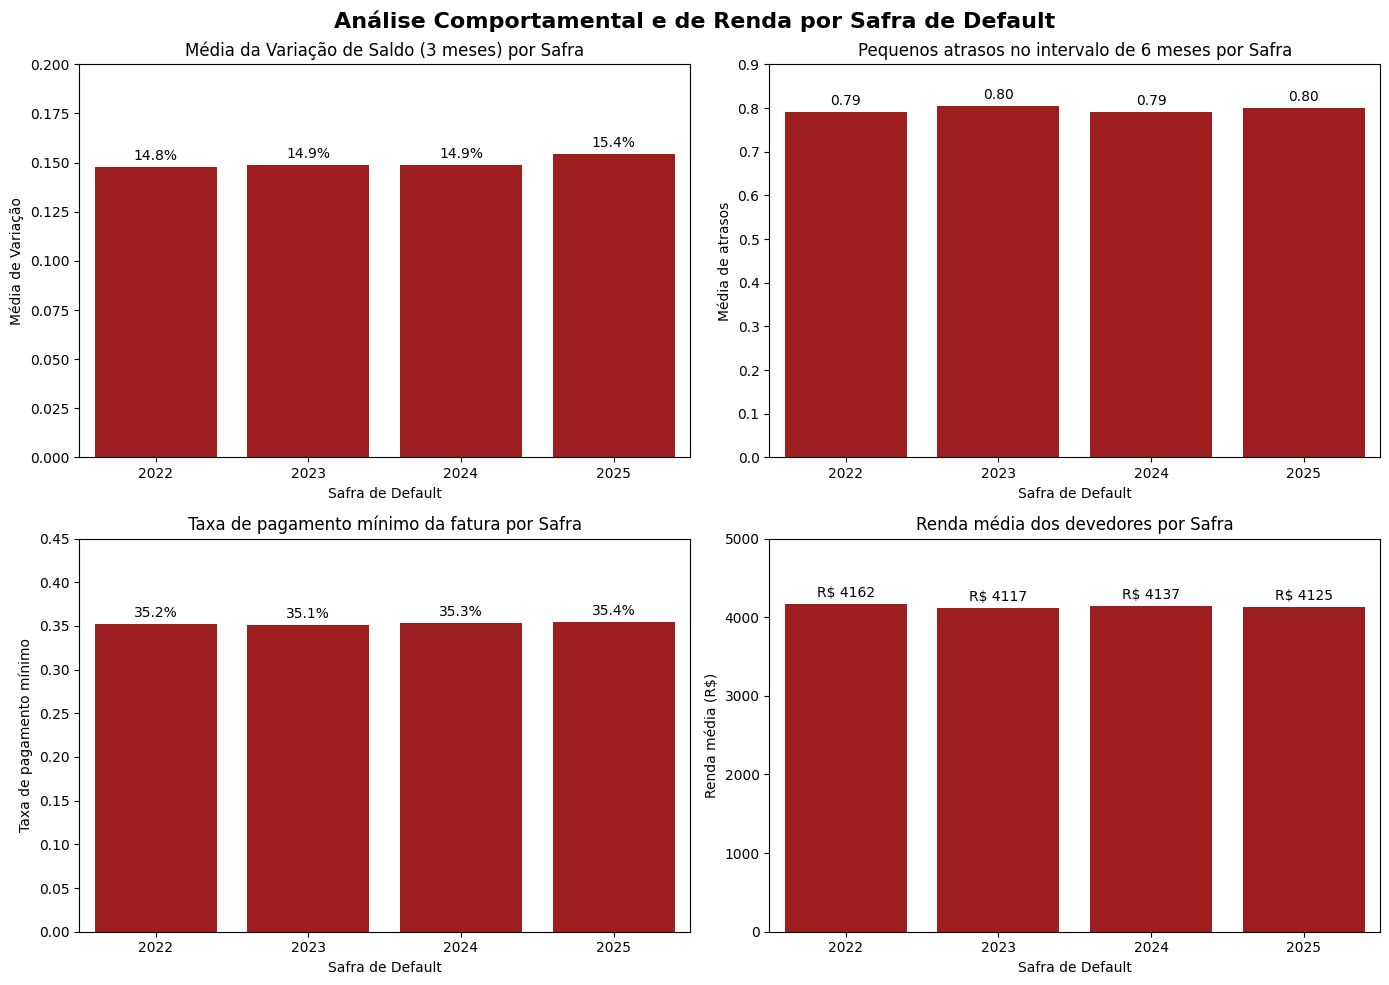

In [7]:
variacao_3m = df_copy.groupby('safra_obs')['variacao_saldo_3m'].mean().reset_index(name='media')
atrasos = df_copy.groupby('safra_obs')['qtd_atrasos_curtos_6m'].mean().reset_index(name='media')
pagamento_minimo = df_copy.groupby('safra_obs')['pagou_minimo_ult_fatura'].mean().reset_index(name='media')
renda_media = df_copy.groupby('safra_obs')['renda_mensal'].mean().reset_index(name='media')


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análise Comportamental e de Renda por Safra de Default', fontsize=16, fontweight='bold')

cor = "#B10909"


sns.barplot(data=variacao_3m, x='safra_obs', y='media', color=cor, ax=axes[0, 0])
axes[0, 0].set_title('Média da Variação de Saldo (3 meses) por Safra', fontsize=12)
axes[0, 0].set_ylabel('Média de Variação')
axes[0, 0].set_xlabel('Safra de Default')
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt=lambda x: f'{x:.1%}', padding=3)
axes[0, 0].set_ylim(0, 0.20) 

sns.barplot(data=atrasos, x='safra_obs', y='media', color=cor, ax=axes[0, 1])
axes[0, 1].set_title('Pequenos atrasos no intervalo de 6 meses por Safra', fontsize=12)
axes[0, 1].set_ylabel('Média de atrasos')
axes[0, 1].set_xlabel('Safra de Default')
axes[0, 1].bar_label(axes[0, 1].containers[0], fmt='%.2f', padding=3)
axes[0, 1].set_ylim(0, 0.90) 


sns.barplot(data=pagamento_minimo, x='safra_obs', y='media', color=cor, ax=axes[1, 0])
axes[1, 0].set_title('Taxa de pagamento mínimo da fatura por Safra', fontsize=12)
axes[1, 0].set_ylabel('Taxa de pagamento mínimo')
axes[1, 0].set_xlabel('Safra de Default')
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt=lambda x: f'{x:.1%}', padding=3)
axes[1, 0].set_ylim(0, 0.45)  # Dá uma folga no topo para o texto não encostar na borda


sns.barplot(data=renda_media, x='safra_obs', y='media', color=cor, ax=axes[1, 1])
axes[1, 1].set_title('Renda média dos devedores por Safra', fontsize=12)
axes[1, 1].set_ylabel('Renda média (R$)')
axes[1, 1].set_xlabel('Safra de Default')
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt='R$ %.0f', padding=3)
axes[1, 1].set_ylim(0, 5000)


plt.tight_layout()
plt.show()

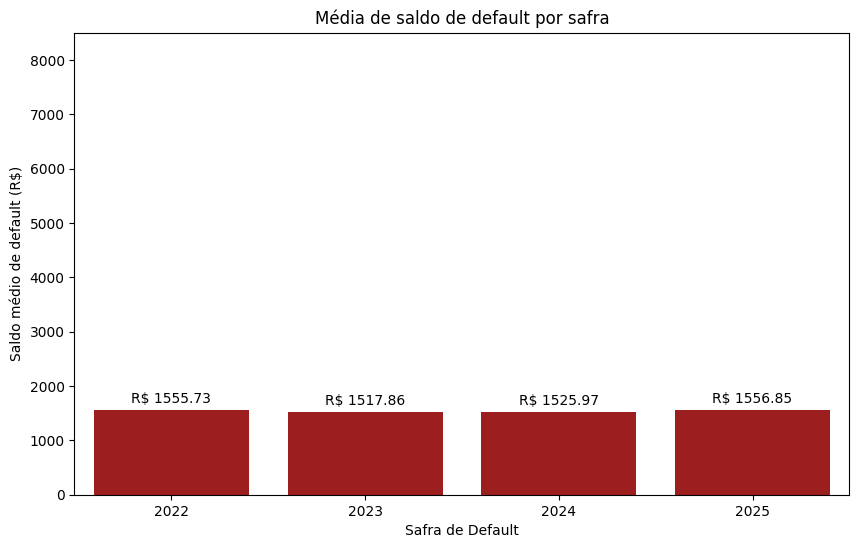

In [8]:
saldo = df_copy.groupby('safra_obs')['saldo_default'].mean().reset_index(name='media')

plt.figure(figsize=(10, 6))
sns.barplot(data=saldo, x='safra_obs', y='media', color=cor)
plt.bar_label(plt.gca().containers[0], fmt='R$ %.2f', padding=3)
plt.ylim(0, 8500)
plt.xlabel('Safra de Default')
plt.ylabel('Saldo médio de default (R$)')
plt.title('Média de saldo de default por safra')
plt.show()

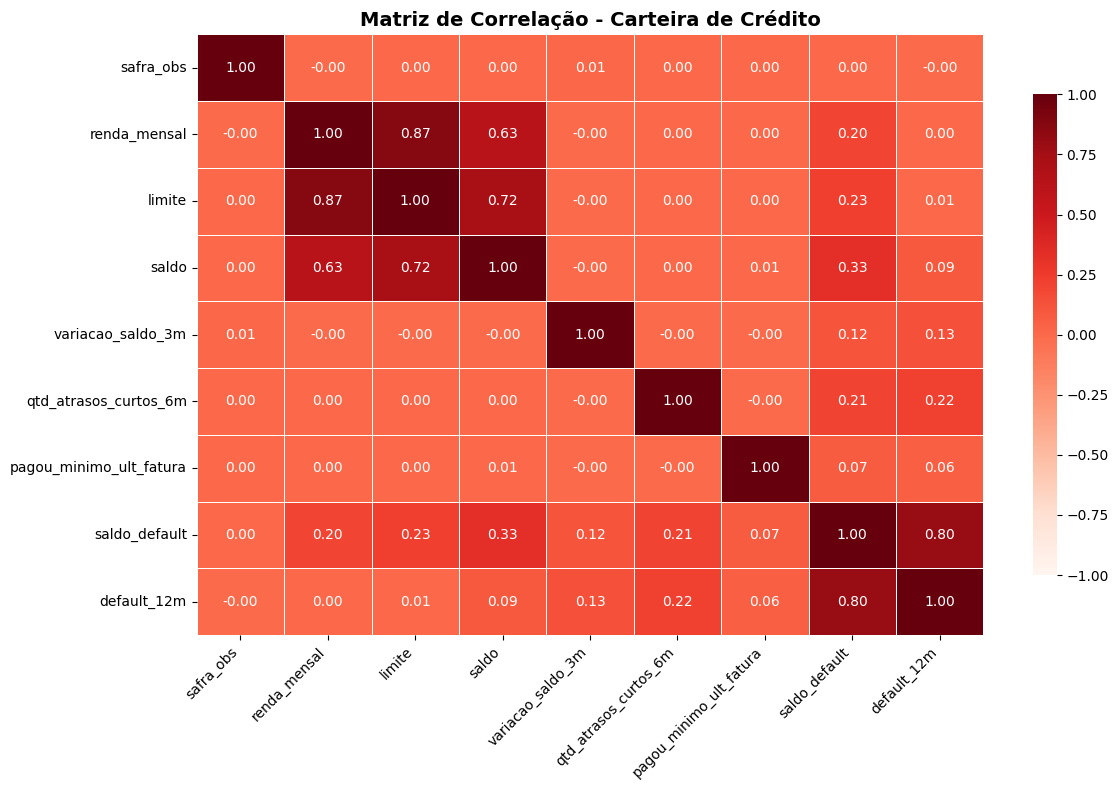

In [9]:
corr = df_copy.corr(numeric_only = True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot = True,           
    fmt = ".2f",            
    cmap= "Reds",          
    vmin=-1, vmax=1,      
    linewidths = 0.5,       
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de Correlação - Carteira de Crédito", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Filtragem da base e criação da variável alvo (`ccf_realizado`)

Preparação da amostra para modelagem e definição do *target*:

* **Filtro de elegibilidade:** Manter apenas os clientes que possuíam limite disponível 12 meses antes do default (`limite > saldo`), evitando divisão por zero no cálculo do CCF.
* **Limite livre:** Criar a coluna `limite_livre` a partir da diferença entre o limite e o saldo (`limite - saldo`).
* **Target (CCF):** Calcular o fator de conversão de crédito realizado:
  $$\text{CCF}_{\text{realizado}} = \frac{\text{saldo\_default} - \text{saldo}}{\text{limite\_livre}}$$
* **Tratamento de extremos (*Clipping*):** Restringir os valores de `ccf_realizado` ao intervalo entre `0` e `1` para evitar distorções causadas por *outliers*.

Como  a fórmula a ser seguida é:

* **Cálculo do Alvo Histórico (CCF Realizado):**
  $$\text{CCF}_{\text{realizado}} = \frac{\text{Saldo no Default} - \text{Saldo}}{\text{Limite} - \text{Saldo}}$$

Vamos selecionar apenas os clientes que possuam um limite nos últimos 12 meses maior que o saldo devedor no mesmo período, assim evitando uma divisão por zero e colapsando fórmula.

In [10]:
df_copy.query("default_12m == 1 and limite > saldo", inplace= True)

df_copy['limite_livre'] = df_copy['limite'] - df_copy['saldo']

#ccf_bruto = (df_copy["saldo_default"] - df_copy["saldo_12m"]) / df_copy["limite_livre_12m"]

df_copy['ccf_bruto'] = (df_copy['saldo_default'] - df_copy['saldo']) / df_copy['limite_livre']

df_copy

,safra_obs,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,default_12m,limite_livre,ccf_bruto
7,2025,14480.06,22471.18,17661.83,0.1905,1,0,19083.57,1,4809.35,0.295620
20,2024,3512.49,7954.09,3454.07,0.3274,1,1,5099.79,1,4500.02,0.365714
21,2022,2380.52,5852.22,2683.43,0.2501,3,1,4806.32,1,3168.79,0.669937
26,2022,2056.70,7071.24,4268.54,-0.2302,1,0,4831.06,1,2802.70,0.200706
27,2024,5869.49,12261.55,1433.31,0.2174,2,1,6661.88,1,10828.24,0.482864
...,...,...,...,...,...,...,...,...,...,...,...
59977,2023,6816.33,12154.74,5862.87,0.5141,1,0,9259.19,1,6291.87,0.539795
59982,2023,4295.69,7745.61,2027.70,0.0338,1,0,3314.73,1,5717.91,0.225087
59983,2023,6050.57,15312.40,11733.88,0.3615,0,1,13679.21,1,3578.52,0.543613
59986,2025,2158.59,4484.15,2871.68,0.5079,1,1,4036.17,1,1612.47,0.722178


* **Tratamento de extremos (*Clipping*):** Utilizar `np.clip(..., 0.0, 1.0)` para restringir os valores de `ccf_realizado` ao intervalo entre `0.0` e `1.0`, evitando distorções causadas por *outliers*.

In [11]:
df_copy['ccf_realizado'] = np.clip(df_copy['ccf_bruto'], 0, 1)
df_copy

,safra_obs,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,default_12m,limite_livre,ccf_bruto,ccf_realizado
7,2025,14480.06,22471.18,17661.83,0.1905,1,0,19083.57,1,4809.35,0.295620,0.295620
20,2024,3512.49,7954.09,3454.07,0.3274,1,1,5099.79,1,4500.02,0.365714,0.365714
21,2022,2380.52,5852.22,2683.43,0.2501,3,1,4806.32,1,3168.79,0.669937,0.669937
26,2022,2056.70,7071.24,4268.54,-0.2302,1,0,4831.06,1,2802.70,0.200706,0.200706
27,2024,5869.49,12261.55,1433.31,0.2174,2,1,6661.88,1,10828.24,0.482864,0.482864
...,...,...,...,...,...,...,...,...,...,...,...,...
59977,2023,6816.33,12154.74,5862.87,0.5141,1,0,9259.19,1,6291.87,0.539795,0.539795
59982,2023,4295.69,7745.61,2027.70,0.0338,1,0,3314.73,1,5717.91,0.225087,0.225087
59983,2023,6050.57,15312.40,11733.88,0.3615,0,1,13679.21,1,3578.52,0.543613,0.543613
59986,2025,2158.59,4484.15,2871.68,0.5079,1,1,4036.17,1,1612.47,0.722178,0.722178


## Engenharia de Atributos (*Feature Engineering*)

Criação de novas variáveis utilizando **apenas dados observados 12 meses antes do default** (evitando *data leakage*):

* **Novas razões financeiras:**
  * `taxa_utilizacao`: razão entre `saldo` e `limite`.
  * `comprometimento_renda`: razão entre `saldo_` e `renda_mensal`.
* **Seleção de variáveis (`features`):** Definição da lista contendo apenas as variáveis explicativas válidas para a modelagem:
  * `limite`, `saldo`, `limite_livre`, `taxa_utilizacao_12m`, `comprometimento_renda`, `variacao_saldo_3m`, `qtd_atrasos_curtos_6m`, `pagou_minimo_ult_fatura`.

In [12]:
df_copy['taxa_utilizacao'] = df_copy['saldo'] / df_copy['limite']

df_copy['comprometimento_renda'] = df_copy['saldo'] / df_copy['renda_mensal']

In [13]:
df_copy.columns

Index(['safra_obs', 'renda_mensal', 'limite', 'saldo', 'variacao_saldo_3m',
       'qtd_atrasos_curtos_6m', 'pagou_minimo_ult_fatura', 'saldo_default',
       'default_12m', 'limite_livre', 'ccf_bruto', 'ccf_realizado',
       'taxa_utilizacao', 'comprometimento_renda'],
      dtype='object')

In [14]:
features = ['limite', 'saldo', 'qtd_atrasos_curtos_6m', 'pagou_minimo_ult_fatura', 'variacao_saldo_3m' , 'taxa_utilizacao', 'comprometimento_renda']

## Divisão Temporal (*Out-of-Time* — OOT)

Separação do dataset por safra, preservando a ordem cronológica (sem embaralhamento) para simular o comportamento real em produção:

* **Base de Treino (`treino`):** registros referentes às safras `safra_obs` de `2022`, `2023` e `2024`.
* **Base de Teste (`teste_oot`):** registros referentes à safra futura `safra_default == 2025`.

In [15]:
treino = df_copy[df_copy['safra_obs'].isin([2022, 2023, 2024]) ].copy()

alvo = treino['ccf_realizado']

teste = df_copy[df_copy['safra_obs'] == 2025].copy()


### Treinar o Modelo de Machine Learning
- Instanciar o `HistGradientBoostingRegressor` definindo hiperparâmetros conservadores para evitar *overfitting* (ex.: `max_depth=4`, `learning_rate=0.05`, `max_iter=200`, `random_state=42`).
- Treinar o modelo (`.fit()`) passando `treino[features]` como entrada (`X`) e `treino["ccf_realizado"]` como alvo (`y`).

In [16]:
modelo_ccf = HistGradientBoostingRegressor(
    max_depth = 4,
    learning_rate = 0.05,
    max_iter = 200,
    random_state = 42 
)



modelo_ccf.fit(treino[features], alvo)

HistGradientBoostingRegressor(learning_rate=0.05, max_depth=4, max_iter=200,
                              random_state=42)

### Prever o CCF e Calcular o EAD na Base de Teste
- Gerar previsões do CCF na base `teste` usando `.predict([features])` e aplicar `np.clip(..., 0.0, 1.0)` para salvar na coluna `ccf_previsto`.
- Converter o percentual previsto em valor financeiro (`ead_previsto`) aplicando a equação geral do EAD na base `teste`.


* **Equação Geral do EAD (Previsão em R$):**
  $$\text{EAD} = \text{Saldo Atual} + \text{CCF}_{\text{previsto}} \times (\text{Limite Total} - \text{Saldo Atual})$$

In [17]:
previsoes = modelo_ccf.predict(teste[features])
teste['ccf_previsto'] = np.clip(previsoes, 0.0, 1.0)


teste["ead_previsto"] = (teste["saldo"] + teste["ccf_previsto"] * teste["limite_livre"] ).round(2)


### Passo 7: Avaliar o Desempenho do Modelo
- **Erro do CCF:** Calcular o `mean_absolute_error` entre `ccf_realizado` e `ccf_previsto`.
- **Erro Financeiro do EAD:** Calcular o `mean_absolute_error` (MAE) e o `root_mean_squared_error` (RMSE) comparando `saldo_default` (real) com `ead_previsto`.
- **Calibração da Carteira:** Comparar a média de `saldo_default` com a média de `ead_previsto` na safra 2025 para verificar se o modelo está bem calibrado no agregado.

In [18]:
mae_ccf = mean_absolute_error(teste["ccf_realizado"], teste["ccf_previsto"])
r2_ccf = r2_score(teste["ccf_realizado"], teste["ccf_previsto"])
mae_ead = mean_absolute_error(teste["saldo_default"], teste["ead_previsto"])
rmse_ead = root_mean_squared_error(teste["saldo_default"], teste["ead_previsto"])
r2_ead = r2_score(teste["saldo_default"], teste["ead_previsto"])

print(f"Base filtrada (com limite livre > 0): {len(df_copy)} de {len(df)} clientes")
print(f"Erro Médio Absoluto (MAE) do CCF: {mae_ccf:.4f} (cerca de {mae_ccf:.1%} de erro médio)")
print(f"Erro Médio Absoluto (MAE) do EAD: R$ {mae_ead:,.2f}")
print(f"Raiz do Erro Quadrático (RMSE) do EAD: R$ {rmse_ead:,.2f}")

print(f'O score R² do modelo de EAD treinado com os dados é: {round(r2_ead,3)}')

Base filtrada (com limite livre > 0): 10977 de 60000 clientes
Erro Médio Absoluto (MAE) do CCF: 0.0592 (cerca de 5.9% de erro médio)
Erro Médio Absoluto (MAE) do EAD: R$ 315.51
Raiz do Erro Quadrático (RMSE) do EAD: R$ 504.14
O score R² do modelo de EAD treinado com os dados é: 0.992


In [19]:
print(f"CALIBRAÇÃO (Média Real vs. Prevista na safra 2025):")
print(f"EAD Médio Real: R$ {teste['saldo_default'].mean():,.2f} | EAD Médio Previsto: R$ {teste['ead_previsto'].mean():,.2f}")


CALIBRAÇÃO (Média Real vs. Prevista na safra 2025):
EAD Médio Real: R$ 8,238.05 | EAD Médio Previsto: R$ 8,236.83


In [20]:
teste['faixa'] = pd.qcut(teste['limite_livre'], 5, labels=False, duplicates='drop')

print(teste.groupby('faixa').agg(
    real=('saldo_default', 'mean'),
    previsto=('ead_previsto', 'mean')
).assign(dif_pct=lambda x: (x['previsto'] / x['real'] - 1) * 100).round(2))

           real  previsto  dif_pct
faixa                             
0       6498.44   6496.75    -0.03
1       6754.33   6759.25     0.07
2       7355.86   7369.76     0.19
3       8881.73   8883.61     0.02
4      11703.07  11677.95    -0.21


In [21]:
print("\nExemplo de 5 clientes da safra de teste (2025):")
colunas_exibir = ["limite", "saldo", "ccf_realizado", "ccf_previsto", "saldo_default", "ead_previsto"]
print(teste[colunas_exibir].head(5).to_string(index=False))


Exemplo de 5 clientes da safra de teste (2025):
  limite    saldo  ccf_realizado  ccf_previsto  saldo_default  ead_previsto
22471.18 17661.83       0.295620      0.400201       19083.57      19586.53
 9529.15  1574.19       0.223660      0.230373        3353.40       3406.80
 2732.79   251.83       0.450027      0.367612        1368.33       1163.86
10681.02  1166.72       0.778841      0.670383        8576.85       7544.94
11057.75  5746.86       0.598135      0.492138        8923.49       8360.55


### Regra de Produção para Toda a Carteira
- Vamos criar uma função `prever_ead_carteira_completa(df_carteira, modelo)` que receba qualquer cliente (inclusive aqueles filtrados na segunda etapa por já estarem com 100% do limite utilizado) e aplique:
  - Se `limite_livre_12m > 0`: calcula o EAD usando o CCF previsto pelo modelo.
  - Caso contrário (`limite_livre_12m <= 0`): define o EAD como sendo o próprio `saldo_12m`.

In [22]:
def prever_ead_carteira_completa(df_carteira, modelo_ccf):
    
    dados = df_carteira.copy()
    dados['limite_livre'] = dados['limite'] - dados['saldo']
    dados['taxa_utilizacao'] = dados['saldo'] / dados['limite']
    dados['comprometimento_renda'] = dados['saldo'] / dados['renda_mensal']

    ccf_estimado = np.clip(modelo_ccf.predict(dados[features]), 0.0, 1.0)

    ead_final = np.where(
        dados['limite_livre'] > 0,
        dados['saldo'] + ccf_estimado * (dados['limite_livre']),
        dados['saldo']
    )

    return pd.Series(ead_final, index = df_carteira.index).round(2)

Carteira fictícia com cenários para teste rápido

In [23]:
novos_clientes = pd.DataFrame({
    'renda_mensal': [6000.0, 3500.0, 2800.0, 4500.0, 8000.0],
    'limite': [12000.0, 7000.0, 5000.0, 9000.0, 15000.0],
    'saldo': [1500.0, 3500.0, 4200.0, 9000.0, 0.0],
    'variacao_saldo_3m': [-0.10, 0.20, 0.55, 0.05, 0.00],
    'qtd_atrasos_curtos_6m': [0, 1, 3, 2, 0],
    'pagou_minimo_ult_fatura': [0, 0, 1, 1, 0]
})

novos_clientes['ead_previsto'] = prever_ead_carteira_completa(novos_clientes, modelo_ccf)
novos_clientes

,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,ead_previsto
0,6000.0,12000.0,1500.0,-0.10,0,0,2046.17
1,3500.0,7000.0,3500.0,0.20,1,0,4693.44
2,2800.0,5000.0,4200.0,0.55,3,1,4934.28
3,4500.0,9000.0,9000.0,0.05,2,1,9000.00
4,8000.0,15000.0,0.0,0.00,0,0,842.01
